# Exercise 3: Decoding and Evaluation

This session is based on the lecture about Machine Translation and focuses on decoding (3.1) and evaluation (3.2). These topics are relevant for all generative models (including LLMs), though exact implementations may vary across different tasks.

Relevant SLP chapters:
* Chapter 7.4 on sampling
* Chapter 12

For this exercise you need to manipulate PyTorch tensors.
If you're not familiar with this, you can take a look at these tutorials:
* [Tensor Basics](https://docs.pytorch.org/tutorials/beginner/basics/tensorqs_tutorial.html)
* [Introduction to PyTorch Tensors](https://docs.pytorch.org/tutorials/beginner/introyt/tensors_deeper_tutorial.html)


## Exercise 3.1: Decoding Strategies
As discussed in the slides and in the book, neural machine translation generally works using a *sequence-to-sequence* architecture.
This is often modeled as an encoder and a decoder:
* the **encoder** component processes the full input sequence into a series of vector representations.
* The **decoder** then uses the representations to generate the target sequence token by token.

At every timestep during the decoding, the decoder generates a probability distribution over its entire vocabulary. This prediction is conditioned on two things: the information from the encoder and the tokens that have already been generated in the previous steps.

In other words, at each timestep the model predicts the most likely next token given the full source sequence and the target tokens predicted so far.

There are a lot of choices regarding *how* we handle the output of the decoder:

* Do we always pick the token with the highest probability?
* Do we do keep alternative options in mind?
* Which and how many hypotheses do we keep track of?
* What about memory and efficiency (time) considerations?

These types of questions are related to the general problems of *sampling* and *decoding*.
This is a fundamental aspect in dealing with generative language models (if you've used any LLM and seen a 'temperature' parameter, it's directly related to this decoding process).

We are going to look at some decoding strategies, using a small, pre-trained NL $\rightarrow$ EN encoder-decoder translation model.

This is a 'fill in the blank' exercise, the parts for you to implement are marked.

**IMPORTANT**

If you're using Google Colab, make sure to select either a TPU or GPU runtime!

Top right: "Connect" -> drop down menu -> "Change runtime type" -> GPU or TPU

Otherwise the inference will take a lot of time.

In [ ]:
!pip install -q transformers tqdm torch ipywidgets sentencepiece sacrebleu pandas seaborn  # This will take a bit

In [ ]:
import dataclasses
import time
from copy import deepcopy
from pathlib import Path
import io

import pandas as pd
import sacrebleu
import seaborn as sns
import torch
import tqdm
from transformers import AutoModelForSeq2SeqLM, T5Tokenizer

In [ ]:
# Classes to keep track of results and sequences

@dataclasses.dataclass
class EvaluationResult:
    bleu: float
    chrf: float
    chrf_pp: float


@dataclasses.dataclass
class ScoredToken:
    """
    Represents a token and a corresponding score, which should roughly translate to the likelihood this
    token should be appended to some given generation sequence.
    """

    token_id: int
    score: float


class GeneratedSequence:
    """
    Represents a sequence in the process of being generated; an initial token, a potential end token, and a series of
    ScoredTokens between them. This class also maintains the overall sequence score, which is the cumulative probability
    of this generated sequence being the best output given some query.
    """

    def __init__(self, initial_token, end_token_id, initial_score):
        self.end_token_id = end_token_id
        self._score = initial_score  # Cumulative log probs of this sequence
        self.normalized_score = initial_score
        self.sequence = [ScoredToken(initial_token, initial_score)]

    def append(self, scored_token):
        """
        Append the given ScoredToken to this sequence; add its log-probability to this
        sequence's total cumulative log-prob
        """
        self.sequence.append(scored_token)
        self._score += scored_token.score
        self.normalized_score = self._score / len(self.sequence)

    def ids(self):
        return [st.token_id for st in self.sequence]

    def has_ended(self):
        """
        Returns True if the last token in this sequence is the end-of-sequence token ID
        """
        return self.sequence and self.sequence[-1].token_id == self.end_token_id

    def __str__(self):
        return f"{self._score: .6f}({self.normalized_score: .6f}): {self.sequence}"

    def __repr__(self):
        return self.__str__()

    def __copy__(self):
        gs = GeneratedSequence(None, self.end_token_id, 0.0)
        gs.sequence = self.sequence.copy()
        gs._score = self._score
        gs.normalized_score = self.normalized_score
        return gs

    # We need the methods below to be able to sort instances of this class.
    def __iter__(self):
        return self.sequence.__iter__()

    def __lt__(self, other_sequence):
        return self.normalized_score < other_sequence.normalized_score

    def __le__(self, other_sequence):
        return self.normalized_score <= other_sequence.normalized_score

    def __eq__(self, other_sequence):
        return (abs(self.normalized_score - other_sequence.normalized_score) <= 1e-5 and self.ids() == other_sequence.ids())

    def __ne__(self, other_sequence):
        return not (self == other_sequence)

    def __gt__(self, other_sequence):
        return self.normalized_score > other_sequence.normalized_score

    def __ge__(self, other_sequence):
        return self.normalized_score >= other_sequence.normalized_score

In [ ]:
# Some convenience functions

def detect_device():
    """Choose the device to run the model on."""
    return torch.device("cuda" if torch.cuda.is_available() else "cpu")


def evaluate(hypotheses, references):
    """Evaluate hypotheses generated by a model with the gold references."""
    bleu = sacrebleu.corpus_bleu(hypotheses, [references]).score
    chrf = sacrebleu.corpus_chrf(hypotheses, [references]).score
    chrf_pp = sacrebleu.corpus_chrf(
        hypotheses,
        [references],
        word_order=2,
        char_order=6,
        beta=2,
        eps_smoothing=False,
    ).score

    return EvaluationResult(bleu, chrf, chrf_pp)

### Task 3.1.1 Greedy Search

In [ ]:
def greedy_search(
    model,
    src_input_ids: torch.Tensor,
    start_token_id: int,
    end_token_id: int,
    device: torch.device,
    max_length: int = 64,
):
    """
    Performs greedy search over the output from model.
    At every time step, this procedure will pick the token with
    the highest (log) probability and continue to the next time step.
    """
    # The output sequence starts as a tensor containing just the start token ID
    output_sequence = torch.full((1, 1), start_token_id, device=device)

    for _ in range(max_length - 1):
        # Predict next token, given input context IDs and output sequence so far
        output = model(input_ids=src_input_ids, decoder_input_ids=output_sequence)

        # Extract the raw model output
        logits = output.logits[:, -1, :]

        # Extract the argmax, the highest-scoring element, from the model output logits.
        # Unsqueeze to remove the singular batch dimension.
        next_token_id = logits.argmax(-1).unsqueeze(-1)

        # Concatenate the next token ID into the output sequence
        output_sequence = torch.cat([output_sequence, next_token_id], dim=-1)

        # If the next token happens to be the end-of-sequence token, break the loop
        if next_token_id == end_token_id:
            break

    # Return greedily-computed output token sequence
    return output_sequence

### Task 3.1.2 Beam Search

In [ ]:
def beam_search(
    tokenizer,
    model,
    src_input_ids: torch.Tensor,
    start_token_id: int,
    end_token_id: int,
    device: torch.device,
    beam_width: int = 8,
    temperature: float = 1.0,
    max_length: int = 64,
    verbose: bool = True,
) -> list[GeneratedSequence]:
    """
    Performs a beam search to generate heuristically-determined best top-k text sequences from a model.

    Args:
    tokenizer (Tokenizer): Tokenizer instance used for token manipulation.
    model (Model): The model used for generating predictions.
    src_input_ids (torch.Tensor): Source input ids for which output needs to be generated.
    start_token_id (int): The token id used to start the sequence generation.
    end_token_id (int): The token id that indicates the end of a sequence.
    device (torch.device): The device (CPU/GPU) where tensors should be allocated.
    beam_width (int, optional): The number of sequences to keep at each step of the beam search. Default is 8.
    temperature (float, optional): A factor used to model the confidence of the predictions.
                                   A higher temperature results in more diversified outputs. Default is 1.0.
    max_length (int, optional): The maximum length of the sequence to be generated. Default is 64.
    verbose (bool, optional): Flag to log detailed outputs of candidates and beam search process.

    Returns:
    A list of generated sequences, where each sequence is represented as an object containing sequence ids, score,
    and tokenized representation.

    Description:
    This function initiates a beam search algorithm to generate sequences from a given model. The search begins with a sequence
    containing only the start_token_id. At each step, the model predicts the next token for each sequence in the current set of
    candidate sequences. The top 'beam_width' tokens and their probabilities are used to extend the current sequences. This process
    repeats until the sequences reach the maximum specified length or all sequences end with the end_token_id.
    """
    # The initial candidate sequence is simply the start token ID with a sequence score of 0
    # This list will be overwritten after an iteration of further generating the candidates!
    candidate_sequences = [GeneratedSequence(start_token_id, end_token_id, 0.0)]

    # Build up output sequences until max_length tokens are reached
    for _ in tqdm.tqdm(range(max_length - 1), desc="Generating candidates...", disable=not verbose):
        # Temporary list to store candidates for the next generation step
        next_step_candidates = []

        # Iterate through all candidate sequences; for each, generate the next most likely tokens
        # and add them to the next-step sequnce of candidates
        for candidate in candidate_sequences:
            # Append the candidate sequence as-is to the next-step candidates if it already contains an end-of-sequence token
            if candidate.has_ended():
                next_step_candidates.append(candidate)
                continue

            # Build a tensor out of the candidate IDs; add a single batch dimension
            gen_seq = torch.tensor(candidate.ids(), device=device).unsqueeze(0)

            # Predict next token
            output = model(input_ids=src_input_ids, decoder_input_ids=gen_seq)

            # Extract logits from output
            logits = output.logits[:, -1, :]

            # Scale logits using temperature value
            scaled_logits = logits / temperature

            # Construct probability distribution against scaled logits through softmax activation function
            probs = torch.softmax(scaled_logits, dim=-1)

            # Select top k (beam_width) probabilities and IDs from the distribution
            top_probs, top_ids = probs.topk(beam_width)

            if verbose:
                print(f"{candidate.normalized_score}: [{candidate.ids()}], next token probabilities:")
                for p, w in zip(top_probs.tolist()[0], tokenizer.convert_ids_to_tokens(top_ids.tolist()[0])):
                    print(f"\tp: {p: .6f}: {w}")
                print("\n")

            # For each of the top-k generated tokens, append to this candidate sequence,
            # update its score, and append to the list of next step candidates
            for i in range(beam_width):
                next_token_id = top_ids[:, i].item()  # the new token ID
                next_score = torch.log(top_probs[:, i]).item()  # log-prob of the above token

                new_seq = deepcopy(candidate)

                # Adds the new token to the end of this sequence, and updates its raw and normalized scores
                # Scores are normalized by sequence token length, to avoid penalizing longer sequences
                new_seq.append(ScoredToken(next_token_id, next_score))

                # Append the updated sequence to the next candidate sequence set
                next_step_candidates.append(new_seq)

        if verbose:
            print("Next step candidates:")
            for seq in reversed(sorted(next_step_candidates)):
                print(f"\t{seq.normalized_score: .6f}: [{seq.ids()}]")
            print("\n")

        # 1. Sort the next-step candidates by score (ascending)
        next_step_candidates.sort()

        # 2. Reverse the sorted list so the best candidates come first
        next_step_candidates_descending = list(reversed(next_step_candidates))

        # 3. Select the top-k (beam_width) sequences
        candidate_sequences = next_step_candidates_descending[:beam_width]

        # Break if all sequences in the heap end with the eos_token_id
        if all(seq.has_ended() for seq in candidate_sequences):
            if verbose:
                print("All candidates include EOS, stopping.")
            break

    return candidate_sequences

### Checkpoint

In [ ]:
model_id = "Michielo/mt5-small_nl-en_translation"
tokenizer_id = "Michielo/mt5-small_nl-en_translation"

device = detect_device()

tokenizer = T5Tokenizer.from_pretrained(tokenizer_id)
model = AutoModelForSeq2SeqLM.from_pretrained(model_id)

# The model architecture (T5) uses the pad_token_id as the starting token for
# text generation (https://huggingface.co/docs/transformers/main/en/model_doc/t5)
start_token_id = tokenizer.pad_token_id
end_token_id = tokenizer.eos_token_id

model.to(device)
model.eval()

Loading weights:   0%|          | 0/190 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


MT5ForConditionalGeneration(
  (shared): Embedding(250112, 512)
  (encoder): MT5Stack(
    (embed_tokens): Embedding(250112, 512)
    (block): ModuleList(
      (0): MT5Block(
        (layer): ModuleList(
          (0): MT5LayerSelfAttention(
            (SelfAttention): MT5Attention(
              (q): Linear(in_features=512, out_features=384, bias=False)
              (k): Linear(in_features=512, out_features=384, bias=False)
              (v): Linear(in_features=512, out_features=384, bias=False)
              (o): Linear(in_features=384, out_features=512, bias=False)
              (relative_attention_bias): Embedding(32, 6)
            )
            (layer_norm): MT5LayerNorm()
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (1): MT5LayerFF(
            (DenseReluDense): MT5DenseGatedActDense(
              (wi_0): Linear(in_features=512, out_features=1024, bias=False)
              (wi_1): Linear(in_features=512, out_features=1024, bias=False)
          

In [ ]:
# Some parameters to control the beam search behavior
beam_width = 3
temperature = 1
# Maximum token length of generated output
max_length = 64
# A prompt to append to the input text (we need this to tell the model that the target is English)
prompt = ">>en<< "

In [ ]:
# Input text to translate
source_text = "Jeetje, wat een lawaai!"
# Prepend a prompt in front of the input text
text = f"{prompt}{source_text}"

# Encode the text into a sequence of IDs
input_ids = tokenizer.encode(text, return_tensors="pt").to(device)

# Perform the decoding with greedy search
greedy_generated_ids = greedy_search(
    model,
    input_ids,
    start_token_id,
    end_token_id,
    device,
    max_length,
)
# Decode the token IDs back to strings (we skip special tokens since we're not expecting any)
greedy_decoded_text = tokenizer.decode(greedy_generated_ids.squeeze(), skip_special_tokens=True)

# And now the same, but with beam search
beam_generated_options = beam_search(
    tokenizer,
    model,
    input_ids,
    start_token_id,
    end_token_id,
    device,
    beam_width,
    temperature,
    max_length,
    verbose=False,  # To print what's happening
)
# Get a list of all final candidates and decode them into strings
all_options = tokenizer.batch_decode([seq.ids() for seq in beam_generated_options], skip_special_tokens=True)
beam_options_formatted = "\n".join(
    f"{t} ({s.normalized_score:.5})" for t, s in zip(all_options, beam_generated_options)
)

beam_best_candidate = all_options.pop(0)

print(f"""
Beam search settings: {beam_width=}, {temperature=}, {max_length=}

Input text: {source_text}

-- Greedy Result --
{greedy_decoded_text}

-- Beam Results --
{beam_options_formatted}
""")


Beam search settings: beam_width=3, temperature=1, max_length=64

Input text: Jeetje, wat een lawaai!

-- Greedy Result --
Oh, yeah, that's a noise!

-- Beam Results --
Oh my gosh, what a noise! (-0.32801)
Oh my gosh, that's a noise! (-0.4802)
Little noise! (-0.48673)



In [ ]:
# Now it's time to evaluate what we have
# Remember, our original text was "Jeetje, wat een lawaai!"

# This gold target is what the translation should be (just an example)
gold_target = "Jeez, what a noise!"

greedy_result = evaluate([greedy_decoded_text], [gold_target])
beam_result = evaluate([beam_best_candidate], [gold_target])

print(f"Greedy: {greedy_result}")
print(f"Beam:   {beam_result}")

Greedy: EvaluationResult(bleu=22.089591134157878, chrf=38.157706928433136, chrf_pp=41.06173256467016)
Beam:   EvaluationResult(bleu=51.69731539571708, chrf=65.95318577110265, chrf_pp=68.4984585303716)


If you have implemented the decoding strategies correctly, you should have the following output:

```
Beam search settings: beam_width=3, temperature=1, max_length=64

Input text: Jeetje, wat een lawaai!

-- Greedy Result --
Oh, yeah, that's a noise!

-- Beam Results --
Oh my gosh, what a noise! (-0.32797)
Oh my gosh, that's a noise! (-0.48012)
Little noise! (-0.48669)
```

The evaluation results of the example sentence should be the following:
```
Greedy: EvaluationResult(bleu=22.089591134157878, chrf=38.157706928433136, chrf_pp=41.06173256467016)
Beam:   EvaluationResult(bleu=51.697315395717055, chrf=65.95318577110265, chrf_pp=68.4984585303716)
```

If your results are not close to these, something is incorrect.
If the scores are slightly off, that's fine since floating points can be slightly different between systems.

**Make sure you have the correct output before you continue!**

## Exercise 3.2: Evaluation
We have included a small dataset with some Dutch and English sentence pairs.
Experiment with different parameters and see what happens to the evaluation metrics.
Also make sure to look at the output since that can often times tell you more than an averaged metric.

We have included an example to compare greedy and beam search.

You have to adjust the parameters given to `run_inference`. It's up to you what to experiment with, some basic examples:
1. Try out different temperature values, what do you see? How does this influence the evaluation metrics?
2. Use different beam sizes, what happens to the time it takes to generate the candidates? What about the metrics?
3. Inspect some of the translations (you don't have to be able to speak Dutch, just look at the translations). Do you notice patterns? Common mistakes? Ungrammatical sentences? Can you think of some reasons of why this happens?

The goal here is that you get an intuition about what's involved in this process and what the trade-offs are.

We provide some evaluation data below, we limit the amount of data due to inference taking a long time.

This data is from [No Language Left Behind](https://arxiv.org/abs/2207.04672).

If you want to know more about state-of-the-art machine translation, take a look at the Conference on Machine Translation [WMT](https://www2.statmt.org/wmt26/) and its [proceedings](https://aclanthology.org/venues/wmt/).

In [ ]:
csv_str = """
nld;eng;"Op maandag kondigden wetenschappers van de Stanford University School of Medicine aan dat een nieuw diagnostisch hulpmiddel is uitgevonden dat cellen op type kan ordenen: een piepkleine af te drukken chip die voor waarschijnlijk ongeveer één dollarcent per stuk kan worden geproduceerd met behulp van standaard inkjetprinters.";"On Monday, scientists from the Stanford University School of Medicine announced the invention of a new diagnostic tool that can sort cells by type: a tiny printable chip that can be manufactured using standard inkjet printers for possibly about one U.S. cent each."
nld;eng;"Hoofdonderzoekers zeggen dat dit kan leiden tot een vroege opsporing van kanker, tuberculose, HIV en malaria bij patiënten in arme landen. Hier zijn de overlevingskansen bij een aandoening als borstkanker de helft minder dan in rijke landen.";"Lead researchers say this may bring early detection of cancer, tuberculosis, HIV and malaria to patients in low-income countries, where the survival rates for illnesses such as breast cancer can be half those of richer countries."
nld;eng;"De JAS 39C Gripen stortte rond 09.30 uur lokale tijd (02.30 UTC) neer op de landingsbaan en ontplofte. De luchthaven is hierdoor gesloten voor commerciële vluchten.";"The JAS 39C Gripen crashed onto a runway at around 9:30 am local time (0230 UTC) and exploded, closing the airport to commercial flights."
nld;eng;"De piloot werd geïdentificeerd als majoor Dilokrit Pattavee.";"The pilot was identified as Squadron Leader Dilokrit Pattavee."
nld;eng;"De lokale media meldt dat er tijdens een actie op de luchthaven een brandweerwagen is gekanteld.";"Local media reports an airport fire vehicle rolled over while responding."
nld;eng;"De 28-jaar oude Vidal is drie seizoenen geleden van Sevilla naar Barça overgestapt.";"28-year-old Vidal had joined Barça three seasons ago, from Sevilla."
nld;eng;"Sinds hij verhuisde naar de Catalaanse hoofdstad heeft hij 49 wedstrijden gespeeld voor de club.";"Since moving to the Catalan-capital, Vidal had played 49 games for the club."
nld;eng;"Het protest begon rond 11.00 lokale tijd (UTC+1) op Whitehall, tegenover de door politie bewaakte ingang van Downing Street, de ambtswoning van de premier.";"The protest started around 11:00 local time (UTC+1) on Whitehall opposite the police-guarded entrance to Downing Street, the Prime Minister's official residence."
nld;eng;"Iets na 11.00 uur begonnen betogers het verkeer op de rijbaan in noordelijke richting in Whitehall te blokkeren.";"Just after 11:00, protesters blocked traffic on the northbound carriage in Whitehall."
nld;eng;"Om 11:20 vroeg de politie aan de demonstranten om weer op de stoep te gaan staan, waarbij zij het recht aanhaalde om het recht op protest af te wegen tegen het toenemende verkeer.";"At 11:20, the police asked the protesters to move back on to the pavement, stating that they needed to balance the right to protest with the traffic building up."
nld;eng;"Vanaf 11.29 uur verplaatsten de demonstranten zich richting Whitehall, langs Trafalgar Square, de Strand, Aldwych en Kingsway naar Holborn. Hier werd het Spring Forum van de Conservative Party gehouden in het hotel Grand Connaught Rooms.";"Around 11:29, the protest moved up Whitehall, past Trafalgar Square, along the Strand, passing by Aldwych and up Kingsway towards Holborn where the Conservative Party were holding their Spring Forum in the Grand Connaught Rooms hotel."
nld;eng;"Het onderlinge record van Nadal tegen de Canadees is 7-2.";"Nadal's head to head record against the Canadian is 7–2."
nld;eng;"Eerder leed hij een nederlaag tegen Raonic in de Brisbane Open.";"He recently lost against Raonic in the Brisbane Open."
nld;eng;"Nadal won 88% van de netpunten in de wedstrijd, waardoor hij 76 punten behaalde in de eerste service.";"Nadal bagged 88% net points in the match winning 76 points in the first serve."
nld;eng;"Na de wedstrijd zei De Gravelkoning, 'Ik ben gewoon blij dat ik weer in de laatste rondes van de belangrijkste wedstrijden sta. Ik ga dit proberen te winnen.'";"After the match, King of Clay said, "I am just excited about being back in the final rounds of the most important events. I am here to try to win this.""
nld;eng;"Het overkoepelde begrip de 'Panama Papers' verwijst naar de ongeveer tien miljoen documenten van het Panamese advocatenkantoor Mossack Fonseca die in de lente van 2016 naar de pers zijn gelekt.";""Panama Papers" is an umbrella term for roughly ten million documents from Panamanian law firm Mossack Fonseca, leaked to the press in spring 2016."
nld;eng;"Uit de documenten blijkt dat veertien banken rijke klanten hielpen bij het verbergen van miljarden Amerikaanse dollars aan rijkdommen om belastingen en andere regelgeving te omzeilen.";"The documents showed fourteen banks helped wealthy clients hide billions of US dollars of wealth to avoid taxes and other regulations."
nld;eng;"Volgens de Britse krant The Guardian beheerde Deutsche Bank ongeveer een op de drie van de 1200 hierbij betrokken lege vennootschappen.";"British newspaper The Guardian suggested Deutsche Bank controlled roughly a third of the 1200 shell companies used to accomplish this."
nld;eng;"Er werd wereldwijd geprotesteerd, verschillende strafrechtelijke vervolgingen werden opgestart en de regeringsleiders van IJsland en Pakistan traden af.";"There were protests worldwide, several criminal prosecutions, and the leaders of the governments of Iceland and Pakistan both resigned."
nld;eng;"De in Hongkong geboren Ma studeerde aan de New York University en Harvard Law School en had ooit een Amerikaanse 'green card', een permanente verblijfsvergunning.";"Born in Hong Kong, Ma studied at New York University and Harvard Law School and once held an American permanent resident "green card"."
nld;eng;"Tijdens de verkiezingen liet Hsieh doorschemeren dat Ma gedurende een crisistijd het land zou kunnen ontvluchten.";"Hsieh implied during the election that Ma might flee the country during a time of crisis."
nld;eng;"Volgens Hsieh was de fotogenieke Ma wel stijlvol, maar had ze niet zo bar veel inhoud.";"Hsieh also argued that the photogenic Ma was more style than substance."
nld;eng;"Hoewel deze beschuldigingen werden geuit, won Ma eenvoudig op een platform dat zich hard maakte voor nauwere banden met het Chinese vasteland.";"Despite these accusations, Ma won handily on a platform advocating closer ties with the Chinese mainland."
nld;eng;"De Speler van de Dag is Alex Ovechkin van de Washington Capitals.";"Today's Player of the Day is Alex Ovechkin of the Washington Capitals."
nld;eng;"In de wedstrijd waarin Washington met 5-3 van de Atlanta Thrashers won, maakte hij 2 doelpunten en 2 assists.";"He had 2 goals and 2 assists in Washington's 5-3 win over the Atlanta Thrashers."
nld;eng;"Ovechkins eerste assist van de avond was op het winnende doelpunt van debutant Nicklas Backstrom;";"Ovechkin's first assist of the night was on the game-winning goal by rookie Nicklas Backstrom;"
nld;eng;"Zijn tweede doelpunt van de avond was zijn 60ste van het seizoen. Hierdoor werd hij de eerste speler die sinds het seizoen van 1995-1996 zestig of meer doelpunten scoorde. In dat seizoen bereikten Jaromir Jagr en Mario Lemieux allebei die mijlpaal.";"his second goal of the night was his 60th of the season, becoming the first player to score 60 or more goals in a season since 1995-96, when Jaromir Jagr and Mario Lemieux each reached that milestone."
nld;eng;"Batten stond in 2008 op plaats 190 op de lijst van de 400 rijkste Amerikanen met een geschat vermogen van 2,3 miljard dollar.";"Batten was ranked 190th on the 2008 400 Richest Americans list with an estimated fortune of $2.3 billion."
nld;eng;"In 1950 haalde hij een diploma aan het College of Arts & Sciences aan de universiteit van Virginia en later doneerde hij er veel geld aan.";"He graduated from the College of Arts & Sciences of the University of Virginia in 1950 and was a significant donor to that institution."
nld;eng;"Bij een oproer staken mensen de Abu Ghraib-gevangenis in Irak in brand.";"Iraq's Abu Ghraib prison has been set alight during a riot."
nld;eng;"De gevangenis werd berucht toen misbruik van gevangenen aan het licht kwam, nadat de Amerikaanse strijdkrachten het hadden overgenomen.";"The jail became notorious after prisoner abuse was discovered there after US forces took over."
nld;eng;"Piquet Jr. crashte in de Grand Prix van Singapore in 2008, net nadat Fernando Alonso al vroeg een pitstop maakte, waarbij de safety car de baan opkwam.";"Piquet Jr. crashed in the 2008 Singapore Grand Prix just after an early pit stop for Fernando Alonso, bringing out the safety car."
nld;eng;"Terwijl de wagens vóór Alonso onder de safety car gingen bijtanken, nam hij de koppositie in om de overwinning te pakken.";"As the cars ahead of Alonso went in for fuel under the safety car, he moved up the pack to take victory."
nld;eng;"Piquet jr. werd in 2009 ontslagen na de Grand Prix van Hongarije.";"Piquet Jr. was sacked after the 2009 Hungarian Grand Prix."
nld;eng;"Om precies 8.46 uur werd het doodstil in de stad. Dit was ook precies het moment waarop het eerste vliegtuig zijn doel raakte.";"At exactly 8:46 a.m. a hush fell across the city, marking the exact moment the first jet struck its target."
nld;eng;"Er zijn twee lichtbundels geplaatst die 's nachts omhoog schijnen.";"Two beams of light have been rigged up to point skywards overnight."
nld;eng;"Er wordt momenteel aan vijf nieuwe wolkenkrabbers gebouwd, met een transportcentrum en een gedenkpark in het midden.";"Construction is ongoing for five new skyscrapers at the site, with a transportation center and memorial park in the middle."
nld;eng;"De PBS-show heeft meer dan twintig Emmy's gewonnen en ze zijn korter op de buis dan Mister Rogers' Neighborhood en Sesamstraat.";"The PBS show has more than two-dozen Emmy awards, and its run is shorter only than Sesame Street and Mister Rogers' Neighborhood."
nld;eng;"Elke aflevering van het programma richtte zich op een thema uit een bepaald boek, waarna dat thema verder werd verkend door middel van meerdere verhalen.";"Each episode of the show would focus on a theme in a specific book and then explore that theme through multiple stories."
nld;eng;"Elke show bevatte ook tips voor boeken die kinderen in hun bibliotheek konden vinden.";"Each show would also provide recommendations for books that children should look for when they went to their library."
nld;eng;"John Grant van WNED Buffalo (het station van Reading Rainbow), zei: 'Reading Rainbow liet kinderen zien waarom ze moeten lezen... bracht hen de liefde voor lezen bij - [de show] spoorde kinderen aan om een boek te pakken en te gaan lezen.'";"John Grant, from WNED Buffalo (Reading Rainbow's home station) said "Reading Rainbow taught kids why to read,... the love of reading — [the show] encouraged kids to pick up a book and to read.""
nld;eng;"Sommige mensen, zoals John Grant, geloven dat de serie aan haar eind is gekomen vanwege de financiële crisis en een verschuiving in de filosofie van educatieve televisieprogrammering.";"It is believed by some, including John Grant, that both the funding crunch and a shift in the philosophy of educational television programming contributed to ending the series."
nld;eng;"De storm bevindt zich ongeveer 645 mijl (1040 km) ten westen van de Kaapverdische Eilanden en zal volgens voorspellers waarschijnlijk zijn uitgeraasd voor het vasteland wordt bedreigd.";"The storm, situated about 645 miles (1040 km) west of the Cape Verde islands, is likely to dissipate before threatening any land areas, forecasters say."
nld;eng;"Momenteel bereikt Fred windsnelheden van 105 mijl per uur (165 km/u) en beweegt de strom zich in noordwestelijke richting.";"Fred currently has winds of 105 miles per hour (165 km/h) and is moving towards the northwest."
nld;eng;"Fred is de sterkste tropische orkaan die sinds de komst van satellietbeelden ooit zo ver in het zuiden en oosten van de Atlantische oceaan is gemeten. Het is slechts de derde grote orkaan die ten oosten van 35°W is gemeten.";"Fred is the strongest tropical cyclone ever recorded so far south and east in the Atlantic since the advent of satellite imagery, and only the third major hurricane on record east of 35°W."
nld;eng;"Op 24 september 1759 sloot Arthur Guinness een huurcontract van 9000 jaar voor de St James' Gate Brewery in Dublin, Ierland.";"On September 24, 1759, Arthur Guinness signed a 9,000 year lease for the St James' Gate Brewery in Dublin, Ireland."
nld;eng;"250 jaar later is Guinness een wereldwijd bedrijf dat ieder jaar 10 miljard euro (US$ 14,7 miljard) omzet draait.";"250 years later, Guinness has grown to a global business that turns over 10 billion euros (US$14.7 billion) every year."
nld;eng;"Jonny Reid, bijrijder van het A1GP-team van Nieuw-Zeeland, ging vandaag de geschiedenis boeken in door op legale manier de snelst tijd neer te zetten op de 48-jaar oude Auckland Harbour Bridge in Nieuw-Zeeland.";"Jonny Reid, co-driver for the A1GP New Zealand team, today made history by driving the fastest over the 48-year-old Auckland Harbour Bridge, New Zealand, legally."
nld;eng;"Het lukte dhr. Reid om met Black Beauty, de A1GP-auto van Nieuw-Zeeland, maar liefst 7 keer met een snelheid van meer dan 160 km/u over de brug te rijden.";"Mr Reid managed to drive the New Zealand's A1GP car, Black Beauty at speeds over 160km/h seven times over the bridge."
nld;eng;"De Nieuw-Zeelandse politie kon nauwelijks met hun lasergun vaststellen hoe snel de heer Reid ging, vanwege de lage wegligging van Black Beauty. De enige keer dat de politie het voor elkaar kreeg om de snelheid van de heer Reid vast te stellen, was toen hij het tempo terugbracht tot 160 km/u.";"The New Zealand police had trouble using their speed radar guns to see how fast Mr Reid was going because of how low Black Beauty is, and the only time the police managed to clock Mr Reid was when he slowed down to 160km/h."
"""

In [ ]:
df = pd.read_csv(io.StringIO(csv_str), sep=";", names=["source_lang", "target_lang", "nld_txt", "eng_txt"])
# We prepare our input by adding the prompt to the source sequences
df["source_txt"] = df["nld_txt"].apply(lambda s: f"{prompt}{s}")

df.head()

,source_lang,target_lang,nld_txt,eng_txt,source_txt
0,nld,eng,Op maandag kondigden wetenschappers van de Sta...,"On Monday, scientists from the Stanford Univer...",>>en<< Op maandag kondigden wetenschappers van...
1,nld,eng,Hoofdonderzoekers zeggen dat dit kan leiden to...,Lead researchers say this may bring early dete...,>>en<< Hoofdonderzoekers zeggen dat dit kan le...
2,nld,eng,De JAS 39C Gripen stortte rond 09.30 uur lokal...,The JAS 39C Gripen crashed onto a runway at ar...,>>en<< De JAS 39C Gripen stortte rond 09.30 uu...
3,nld,eng,De piloot werd geïdentificeerd als majoor Dilo...,The pilot was identified as Squadron Leader Di...,>>en<< De piloot werd geïdentificeerd als majo...
4,nld,eng,De lokale media meldt dat er tijdens een actie...,Local media reports an airport fire vehicle ro...,>>en<< De lokale media meldt dat er tijdens ee...


In [ ]:
def run_inference(
    source_texts: list[str],
    model,
    tokenizer,
    decoding_strategy: str,
    start_token_id: int,
    end_token_id: int,
    device: torch.device,
    max_length: int,
    beam_width: int,
    temperature: float,
) -> list[str]:
    """A wrapper function to generate translations for a list of texts."""

    encoded_results = []
    for text in tqdm.tqdm(source_texts, desc="Running inference"):
        sample_ids = tokenizer.encode(text, return_tensors="pt").to(device)
        if decoding_strategy == "greedy":
            generated_ids = greedy_search(
                model,
                sample_ids,
                start_token_id,
                end_token_id,
                device,
                max_length,
            )
            generated_ids = generated_ids.squeeze()
        elif decoding_strategy == "beam":
            beam_generated_options = beam_search(
                tokenizer,
                model,
                sample_ids,
                start_token_id,
                end_token_id,
                device,
                beam_width,
                temperature,
                max_length,
                verbose=False,
            )
            generated_ids = beam_generated_options[0].ids()
        else:
            raise ValueError(f"Unknown decoding strategy: {decoding_strategy}")

        encoded_results.append(generated_ids)

    # Transform all token ids back to strings in one go (a bit faster)
    results = tokenizer.batch_decode(encoded_results, skip_special_tokens=True)

    return results

In [ ]:
# Store the results in the dataframe for further analysis
df["results_greedy"] = run_inference(
    source_texts=df["source_txt"].tolist(),
    model=model,
    tokenizer=tokenizer,
    decoding_strategy="greedy",
    start_token_id=start_token_id,
    end_token_id=end_token_id,
    device=device,
    max_length=64,
    beam_width=3,
    temperature=1,
)
df["results_beam"] = run_inference(
    source_texts=df["source_txt"].tolist(),
    model=model,
    tokenizer=tokenizer,
    decoding_strategy="beam",
    start_token_id=start_token_id,
    end_token_id=end_token_id,
    device=device,
    max_length=64,
    beam_width=3,
    temperature=1,
)

df.head()

Running inference: 100%|██████████| 50/50 [00:46<00:00,  1.07it/s]


,source_lang,target_lang,nld_txt,eng_txt,source_txt,results_greedy,results_beam
0,nld,eng,Op maandag kondigden wetenschappers van de Sta...,"On Monday, scientists from the Stanford Univer...",>>en<< Op maandag kondigden wetenschappers van...,"And on Monday, scientists at Stanford Universi...","On Monday, scientists at Stanford University S..."
1,nld,eng,Hoofdonderzoekers zeggen dat dit kan leiden to...,Lead researchers say this may bring early dete...,>>en<< Hoofdonderzoekers zeggen dat dit kan le...,And heads of research would say that this coul...,And researchers say that this can lead to earl...
2,nld,eng,De JAS 39C Gripen stortte rond 09.30 uur lokal...,The JAS 39C Gripen crashed onto a runway at ar...,>>en<< De JAS 39C Gripen stortte rond 09.30 uu...,The ALS 39C gripes took about 5 p.m. local tim...,The J.C. gripes collapsed around 5 p.m. at 5 p...
3,nld,eng,De piloot werd geïdentificeerd als majoor Dilo...,The pilot was identified as Squadron Leader Di...,>>en<< De piloot werd geïdentificeerd als majo...,The pilot was identified as Major Dilokoro pat...,The pilot was identified as Major Dilokoro pat...
4,nld,eng,De lokale media meldt dat er tijdens een actie...,Local media reports an airport fire vehicle ro...,>>en<< De lokale media meldt dat er tijdens ee...,The local media reports that during an operati...,The local media reports that during an operati...


<Axes: xlabel='metric', ylabel='value'>

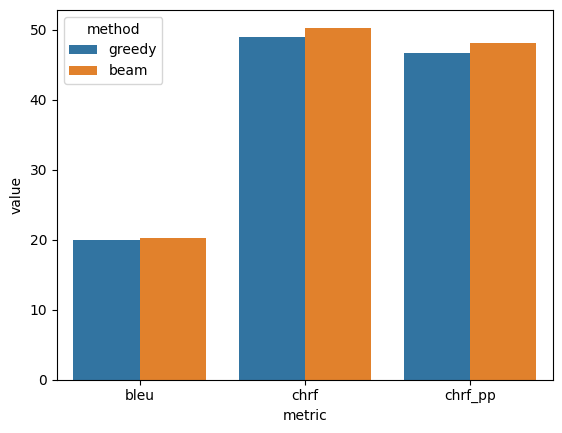

In [ ]:
# This is just an example analysis, you should experiment with different parameters

greedy = evaluate(df["results_greedy"].tolist(), df["eng_txt"].tolist())
beam = evaluate(df["results_beam"].tolist(), df["eng_txt"].tolist())

records = []
for res, label in [(greedy, "greedy"), (beam, "beam")]:
    for key, value in dataclasses.asdict(res).items():
        rec = {"method": label, "metric": key, "value": value}
        records.append(rec)

df_metrics = pd.DataFrame().from_records(records)

sns.barplot(df_metrics, x="metric", y="value", hue="method")